# Proyecto MA4703 Control Óptimo — Avance: Objetivo 7
## Control estocástico del modelo de Black-Scholes (problema de Merton)

* Profesor: Héctor Ramírez.
* Auxiliares: Hernán Torres, Diego Morales.
* Ayudante: Fraick Reyes.
* Integrantes: Bonnie Lagos, Javier Cruz.

**Objetivo de este avance.** Estudiar qué ocurre cuando se acota el tiempo del sistema a un tiempo $T>0$ finito o a un tiempo de parada $\tau$. Incluye la extensión del enunciado "permitir que el sistema se acote a un tiempo finito y que dicho tiempo sea un parámetro modificable".

1. **Horizonte finito $T$** (Secciones 1 a 3): solución explícita, resolución numérica de la HJB parabólica (que ahora depende del tiempo) y efecto de $T$.
2. **Tiempo de parada aleatorio** $\tau\sim\text{Exp}(\lambda)$, independiente del mercado (Sección 4): vida incierta con herencia.
3. **Tiempo de parada que depende del capital** (Sección 5): si el capital cae a un piso $x_\ell$, se liquida la inversión y desde ahí solo se usa el banco. Este caso no tiene solución explícita.

El avance 1 (Sección 8) ya resolvió el horizonte finito con el equivalente cierto y OptimalControl.jl; aquí lo hacemos con **programación dinámica**, con el mismo esquema del avance 4.

**Referencias.** [KS] Karatzas–Shreve; [R] Ross; [KD] Kushner–Dupuis; [CRRA] documento teórico del proyecto.

In [1]:
import Pkg; Pkg.add("Plots")   # LinearAlgebra, Statistics, Random y Printf vienen incluidos en Julia
using Plots, LinearAlgebra, Statistics, Random, Printf

# estilo de los gráficos para el póster: letras grandes y líneas gruesas
default(size=(800, 540), titlefontsize=18, guidefontsize=16, tickfontsize=13, legendfontsize=12,
        linewidth=3, markersize=7, framestyle=:box, gridalpha=0.15, margin=6Plots.mm, dpi=150,
        foreground_color_legend=nothing)
mkpath("figuras_poster");  # cada gráfico se guarda también solo, en PNG de 300 dpi

     Project No packages added to or removed from `C:\Users\bonni\.julia\environments\v1.12\Project.toml`
    Manifest No packages added to or removed from `C:\Users\bonni\.julia\environments\v1.12\Manifest.toml`


In [2]:
# parámetros del modelo (los mismos de los avances anteriores)
const par = (r = 0.03, mu = 0.08, sigma = 0.20, eta = 2.0, gamma = 0.05, x0 = 100.0)

U(c; P=par) = (c^(1 - P.eta) - 1)/(1 - P.eta)                                    # utilidad CRRA
const theta = (par.mu - par.r)/par.sigma                                         # precio de mercado del riesgo
const Pim   = (par.mu - par.r)/(par.eta*par.sigma^2)                             # fracción óptima Pi*
const nu    = (par.gamma - (1 - par.eta)*(par.r + theta^2/(2*par.eta)))/par.eta  # tasa óptima de consumo
V(x; P=par) = (nu^(-P.eta)*x^(1 - P.eta) - 1/P.gamma)/(1 - P.eta)                # valor en horizonte infinito
kappa(Pi, c; P=par) = P.gamma - (1 - P.eta)*(P.r + Pi*(P.mu - P.r) - c - 0.5*P.eta*P.sigma^2*Pi^2)

@printf("Pi* = %.4f   nu = %.6f   V(x0) = %.6f\n", Pim, nu, V(par.x0))

Pi* = 0.6250   nu = 0.047813   V(x0) = 15.625614


## 1. Horizonte finito: solución explícita

Con horizonte $T$ y una **herencia** de peso $\varepsilon\ge0$ (utilidad del capital que queda en $T$), el criterio es
$$
J_T(x;\Pi,C)=\mathbb E_x\Big[\int_0^Te^{-\gamma t}U(C_t)\,dt+\varepsilon\,e^{-\gamma T}U(X_T)\Big],
$$
y la función valor $V(t,x)$ (valor desde el tiempo $t$ con capital $x$) resuelve la HJB **parabólica**
$$
\partial_tV-\gamma V+\sup_{\Pi,\ c\ge0}\Big\{U(c)+\big[(r+\Pi(\mu-r))x-c\big]\partial_xV+\tfrac12\sigma^2\Pi^2x^2\partial_{xx}V\Big\}=0,\qquad V(T,x)=\varepsilon\,U(x).
$$

**Proposición 1.** Sean $s=T-t$ el tiempo que falta,
$$
L(s)=\frac1\nu+\Big(\varepsilon^{1/\eta}-\frac1\nu\Big)e^{-\nu s},\qquad D(s)=\frac{1-e^{-\gamma s}}{\gamma}+\varepsilon\,e^{-\gamma s}.
$$
Entonces $V(t,x)=\frac{1}{1-\eta}\big(L(s)^\eta x^{1-\eta}-D(s)\big)$, y el control óptimo es $\Pi^*=\frac{\mu-r}{\eta\sigma^2}$ (el mismo de horizonte infinito) con consumo $C^*_t=X_t/L(T-t)$.

*Demostración.* Probamos $V=\frac{L^\eta x^{1-\eta}}{1-\eta}+g(t)$. Como en el caso estacionario, el supremo en $\Pi$ da $\Pi^*$ y el supremo en $c$ da $c=L^{-1}x$. Agrupando los términos en $x^{1-\eta}$ queda la EDO $L'=\nu L-1$ (con $'=d/dt$), cuya solución con $L(T)=\varepsilon^{1/\eta}$ es la del enunciado; los términos constantes dan $g'-\gamma g=\frac{1}{1-\eta}$ con $g(T)=-\frac{\varepsilon}{1-\eta}$, cuya solución es $g=-\frac{D(s)}{1-\eta}$. La verificación es la del reporte, ahora en $[0,T]$, sin condición de transversalidad. $\blacksquare$

**Consecuencias.**
* La fracción invertida no depende del horizonte: con utilidad CRRA el inversionista no se vuelve más conservador al acercarse a $T$.
* La tasa de consumo $1/L(s)$ sube a medida que se acerca $T$, hasta $\varepsilon^{-1/\eta}$. **Sin herencia** ($\varepsilon=0$) se tiene $L(s)\approx s$ cerca de $T$, así que $C^*/X\approx\frac{1}{T-t}\to\infty$: el inversionista consume todo su capital.
* Cuando $T\to\infty$, $L(s)\to1/\nu$ y $D(s)\to1/\gamma$: se recupera Merton en horizonte infinito.

In [3]:
D(s, eps; P=par) = (1 - exp(-P.gamma*s))/P.gamma + eps*exp(-P.gamma*s)        # s = T - t
L(s, eps; P=par) = 1/nu + (eps^(1/P.eta) - 1/nu)*exp(-nu*s)
VT(s, x, eps; P=par) = (L(s, eps)^P.eta*x^(1 - P.eta) - D(s, eps))/(1 - P.eta)  # valor con s años por delante

for eps in [0.0, 0.1, 1.0]
    @printf("eps = %.1f:  V(0, x0) con T = 20: %.4f   consumo C/X en t = 0: %.4f,  en t = 19: %.4f,  en t = T: %s\n",
            eps, VT(20.0, par.x0, eps), 1/L(20.0, eps), 1/L(1.0, eps), eps > 0 ? @sprintf("%.4f", 1/L(0.0, eps)) : "infinito")
end

eps = 0.0:  V(0, x0) con T = 20: 10.9843   consumo C/X en t = 0: 0.0777,  en t = 19: 1.0241,  en t = T: infinito
eps = 0.1:  V(0, x0) con T = 20: 10.9897   consumo C/X en t = 0: 0.0769,  en t = 19: 0.7825,  en t = T: 3.1623
eps = 1.0:  V(0, x0) con T = 20: 11.2517   consumo C/X en t = 0: 0.0754,  en t = 19: 0.5182,  en t = T: 1.0000


## 2. La HJB parabólica numérica

Usamos el esquema del avance 4 en $y=\log x$, ahora marchando **hacia atrás en el tiempo** desde $V(T,\cdot)=\varepsilon U$. Con paso $\Delta s$ en $s=T-t$:

* en cada paso calculamos la política $(\Pi,e)$ con las condiciones de primer orden sobre la solución del paso anterior;
* resolvemos el sistema tridiagonal de **Euler implícito**,
$$
\frac{W^{m+1}_i-W^m_i}{\Delta s}=-\gamma W^{m+1}_i+U(e_i\,e^{y_i})+b_i\,(\text{upwind de }W^{m+1})'+a_i\,(W^{m+1})''_i,
$$
que en los nodos interiores sigue siendo una M-matriz (la diagonal gana $1/\Delta s$), así que es estable para cualquier $\Delta s$.

**Proposición 2 (homotecia con horizonte finito).** $x\,\partial_xV(t,x)=(1-\eta)V(t,x)+D(T-t)$.

*Demostración.* Igual que la Prop. 1 del avance 4: escalar el capital por $\lambda$ multiplica $J_T$ por $\lambda^{1-\eta}$ y le suma $\frac{\lambda^{1-\eta}-1}{1-\eta}D(T-t)$ (la herencia aporta el término $\varepsilon e^{-\gamma s}$). Se deriva en $\lambda=1$. $\blacksquare$

Como en el avance 4, en los bordes de la malla usamos esta identidad para escribir la ecuación sin vecinos. No usa $L$, solo la función conocida $D$.

La herencia es necesaria para el esquema: con $\varepsilon=0$ el consumo explota en $T$ y la política del primer paso no está definida ($V(T,\cdot)=0$). Por eso resolvemos numéricamente $\varepsilon=1$ y $\varepsilon=0.1$, y el caso $\varepsilon=0$ lo vemos con la fórmula.

In [4]:
# política por condiciones de primer orden; en los bordes, la identidad de homotecia x V_x = (1 - eta) V + Dv
function politica(W, y, Dv; P=par, emax=50.0)
    n = length(W); k = y[2] - y[1]; x = exp.(y)
    W1, W2 = similar(W), similar(W)
    for i in 2:n-1
        W1[i] = (W[i+1] - W[i-1])/(2k); W2[i] = (W[i+1] - 2W[i] + W[i-1])/k^2
    end
    for i in (1, n)
        W1[i] = (1 - P.eta)*W[i] + Dv; W2[i] = (1 - P.eta)*W1[i]
    end
    W1 = max.(W1, 1e-12)
    e = min.((x .^ (1 - P.eta) ./ W1) .^ (1/P.eta), emax)
    den = P.sigma^2 .* (W2 .- W1)
    Pi = [den[i] < 0 ? clamp(-(P.mu - P.r)*W1[i]/den[i], -5.0, 5.0) : 0.0 for i in 1:n]
    return Pi, e
end

# HJB parabólica hacia atrás desde t = T, con M pasos de Euler implícito.
# Devuelve W(0, .), la política en t = 0 y la tasa de consumo en x0 a lo largo del tiempo.
function resolver_finito(y, T, M; eps=1.0, P=par)
    n = length(y); k = y[2] - y[1]; x = exp.(y); ds = T/M
    i0 = argmin(abs.(x .- P.x0))
    W = eps .* U.(x; P=P)                               # condición final V(T, x) = eps U(x)
    e_x0 = zeros(M)
    for m in 1:M
        Pi, e = politica(W, y, D((m - 1)*ds, eps; P=P); P=P)
        e_x0[m] = e[i0]
        b = P.r .+ Pi .* (P.mu - P.r) .- e .- 0.5*P.sigma^2 .* Pi.^2
        a = 0.5*P.sigma^2 .* Pi.^2
        bp, bm = max.(b, 0), max.(-b, 0)
        dl = -(bm ./ k .+ a ./ k^2)
        d  = 1/ds .+ P.gamma .+ (bp .+ bm) ./ k .+ 2a ./ k^2
        du = -(bp ./ k .+ a ./ k^2)
        rhs = U.(e .* x; P=P) .+ W ./ ds
        for i in (1, n)                                 # bordes: Prop. 2
            dl[i] = 0.0; du[i] = 0.0
            d[i] = 1/ds + kappa(Pi[i], e[i]; P=P)
            rhs[i] = W[i]/ds + U(e[i]*x[i]; P=P) + (b[i] + (1 - P.eta)*a[i])*D(m*ds, eps; P=P)
        end
        W = Tridiagonal(dl[2:n], d, du[1:n-1]) \ rhs
    end
    Pi, e = politica(W, y, D(T, eps; P=P); P=P)
    return (W=W, Pi=Pi, e=e, x=x, s=ds .* (0:M-1), e_x0=e_x0)
end

resolver_finito (generic function with 1 method)

In [5]:
T = 20.0
println("  eps     n     M   W(0,x0)    exacto     error   Pi(0,x0)   C/X en t=0   exacto")
for eps in [1.0, 0.1], (n, M) in [(201, 200), (401, 400), (801, 800), (1601, 1600)]
    y = collect(range(log(1.0), log(1e4), length=n)); i0 = (n + 1) ÷ 2
    s = resolver_finito(y, T, M; eps=eps)
    @printf("%5.1f %5d %5d %9.4f %9.4f %9.1e %9.4f %11.5f %9.5f\n", eps, n, M, s.W[i0], VT(T, par.x0, eps),
            s.W[i0] - VT(T, par.x0, eps), s.Pi[i0], s.e[i0], 1/L(T, eps))
end

  eps     n     M   W(0,x0)    exacto     error   Pi(0,x0)   C/X en t=0   exacto
  1.0   201   200   11.2049   11.2517  -4.7e-02    0.6251     0.07477   0.07541
  1.0   401   400   11.2286   11.2517  -2.3e-02    0.6250     0.07510   0.07541
  1.0   801   800   11.2402   11.2517  -1.1e-02    0.6250     0.07526   0.07541
  1.0  1601  1600   11.2460   11.2517  -5.7e-03    0.6250     0.07533   0.07541
  0.1   201   200   10.9345   10.9897  -5.5e-02    0.6251     0.07610   0.07693
  0.1   401   400   10.9627   10.9897  -2.7e-02    0.6250     0.07653   0.07693
  0.1   801   800   10.9763   10.9897  -1.3e-02    0.6250     0.07673   0.07693
  0.1  1601  1600   10.9830   10.9897  -6.6e-03    0.6250     0.07683   0.07693


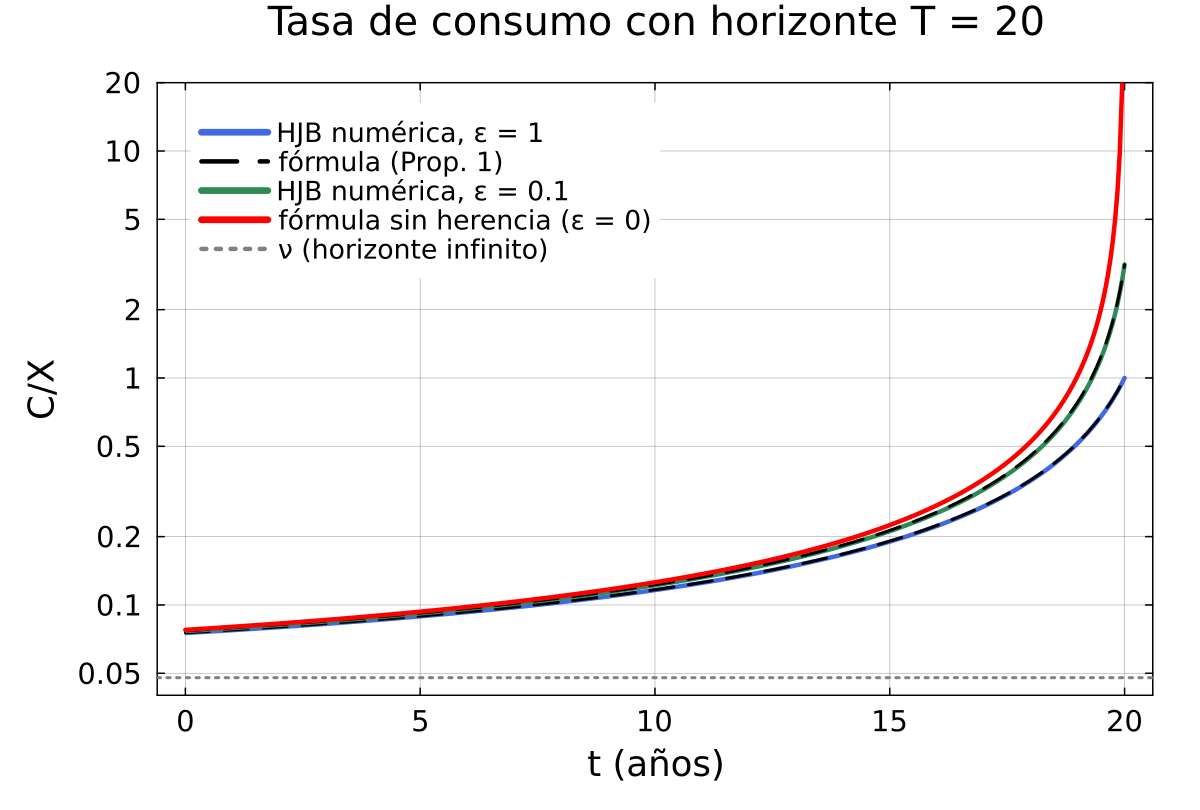

In [6]:
y = collect(range(log(1.0), log(1e4), length=801))
tt = range(0, T - 1e-3, length=400)
pe = plot(xlabel="t (años)", ylabel="C/X", title="Tasa de consumo con horizonte T = 20", yscale=:log10,
          ylims=(0.04, 20), legend=:topleft,
          yticks=([0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20], ["0.05", "0.1", "0.2", "0.5", "1", "2", "5", "10", "20"]))
for (eps, col, txt) in [(1.0, :royalblue, "1"), (0.1, :seagreen, "0.1")]
    s = resolver_finito(y, T, 800; eps=eps)
    plot!(pe, T .- s.s, s.e_x0, color=col, label="HJB numérica, ε = $txt")
    plot!(pe, tt, 1 ./ L.(T .- tt, eps), color=:black, ls=:dash, lw=2, label=(eps == 1.0 ? "fórmula (Prop. 1)" : false))
end
plot!(pe, tt, 1 ./ L.(T .- tt, 0.0), color=:red, label="fórmula sin herencia (ε = 0)")
hline!(pe, [nu], color=:gray, ls=:dot, lw=2, label="ν (horizonte infinito)")
savefig(plot(pe, dpi=300), "figuras_poster/horizonte_consumo.png")
pe

El esquema converge con orden 1 a la solución de la Proposición 1 (el error en $V(0,x_0)$ se divide por dos al duplicar $n$ y $M$), y la fracción numérica en $t=0$ es $\Pi^*=0.625$. En el gráfico, la tasa de consumo numérica sigue a la fórmula $1/L(T-t)$: sube lentamente durante casi todo el horizonte y se dispara en los últimos años, hasta $\varepsilon^{-1/\eta}$ en $t=T$ (1 con $\varepsilon=1$ y 3.16 con $\varepsilon=0.1$). Sin herencia, la fórmula explota como $1/(T-t)$: el inversionista se consume todo el capital antes de $T$. Incluso al inicio se consume más que en horizonte infinito (0.075 frente a $\nu=0.048$), porque hay menos años entre los que repartir el capital.

## 3. El horizonte como parámetro

¿Cuánto importa $T$? Con la Proposición 1 calculamos el valor $V(0,x_0)$ y la tasa de consumo inicial para $T$ entre 1 y 100 años, con y sin herencia, y los comparamos con el horizonte infinito. Agregamos puntos de la HJB numérica para $\varepsilon=1$.

T =  10: V(0,x0) sin herencia =   7.2375, con herencia =   7.7417  (infinito: 15.6256);  C/X inicial = 0.1258 / 0.1167  (nu = 0.0478)
T =  30: V(0,x0) sin herencia =  12.9992, con herencia =  13.1458  (infinito: 15.6256);  C/X inicial = 0.0628 / 0.0618  (nu = 0.0478)
T =  60: V(0,x0) sin herencia =  15.1124, con herencia =  15.1398  (infinito: 15.6256);  C/X inicial = 0.0507 / 0.0505  (nu = 0.0478)
T = 100: V(0,x0) sin herencia =  15.5639, con herencia =  15.5672  (infinito: 15.6256);  C/X inicial = 0.0482 / 0.0482  (nu = 0.0478)


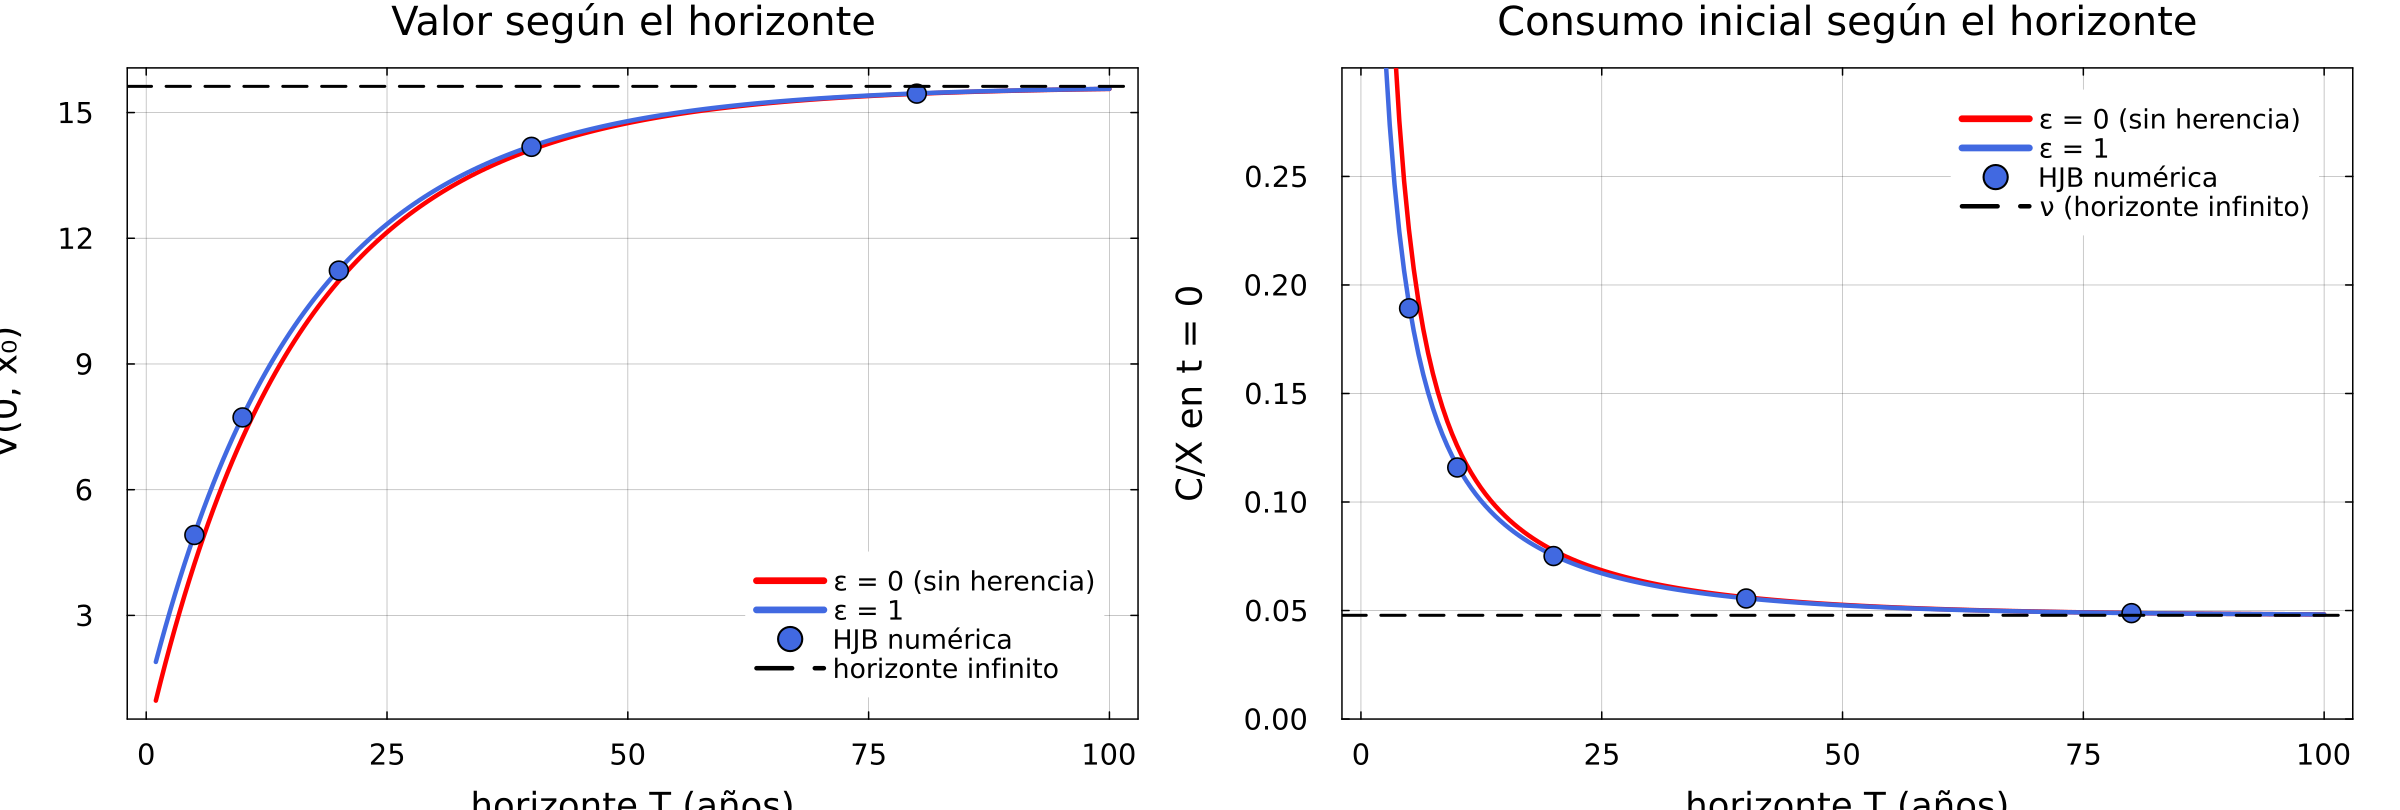

In [7]:
Ts = range(1, 100, length=200)
pv = plot(xlabel="horizonte T (años)", ylabel="V(0, x₀)", title="Valor según el horizonte", legend=:bottomright)
pc = plot(xlabel="horizonte T (años)", ylabel="C/X en t = 0", title="Consumo inicial según el horizonte", legend=:topright,
          ylims=(0, 0.3))
for (eps, col, txt) in [(0.0, :red, "ε = 0 (sin herencia)"), (1.0, :royalblue, "ε = 1")]
    plot!(pv, Ts, VT.(Ts, par.x0, eps), color=col, label=txt)
    plot!(pc, Ts, 1 ./ L.(Ts, eps), color=col, label=txt)
end
Tnum = [5.0, 10.0, 20.0, 40.0, 80.0]
Wnum = [resolver_finito(collect(range(log(1.0), log(1e4), length=401)), Tn, round(Int, 20Tn); eps=1.0) for Tn in Tnum]
scatter!(pv, Tnum, [w.W[201] for w in Wnum], color=:royalblue, label="HJB numérica")
scatter!(pc, Tnum, [w.e[201] for w in Wnum], color=:royalblue, label="HJB numérica")
hline!(pv, [V(par.x0)], color=:black, ls=:dash, lw=2, label="horizonte infinito")
hline!(pc, [nu], color=:black, ls=:dash, lw=2, label="ν (horizonte infinito)")
for Tn in [10, 30, 60, 100]
    @printf("T = %3d: V(0,x0) sin herencia = %8.4f, con herencia = %8.4f  (infinito: %.4f);  C/X inicial = %.4f / %.4f  (nu = %.4f)\n",
            Tn, VT(Tn, par.x0, 0.0), VT(Tn, par.x0, 1.0), V(par.x0), 1/L(Tn, 0.0), 1/L(Tn, 1.0), nu)
end
savefig(plot(pv, dpi=300), "figuras_poster/horizonte_valor.png")
savefig(plot(pc, dpi=300), "figuras_poster/horizonte_consumo_inicial.png")
plot(pv, pc, layout=(1, 2), size=(1600, 540))

El horizonte importa mucho, y por mucho tiempo: con $T=10$ el valor es 7.7, lejos del 15.6 de horizonte infinito, y con $T=60$ todavía hay una diferencia de 0.5. La razón es que $L(s)$ se acerca a $1/\nu$ como $e^{-\nu s}$, con $1/\nu\approx21$ años: hacen falta unos $3/\nu\approx60$ años para que el horizonte deje de importar, y lo mismo pasa con la tasa de consumo inicial. La herencia aumenta el valor y baja el consumo inicial, pero su efecto desaparece en horizontes largos porque está descontada por $e^{-\gamma T}$. La HJB numérica coincide con la fórmula en todos los horizontes probados.

## 4. Tiempo de parada aleatorio: vida incierta

Ahora el sistema se detiene en un tiempo aleatorio $\tau\sim\text{Exp}(\lambda)$ independiente del browniano (por ejemplo, la muerte del inversionista, con esperanza $1/\lambda$ años), y en $\tau$ se deja una herencia $\varepsilon\,U(X_\tau)$:
$$
J=\mathbb E_x\Big[\int_0^\tau e^{-\gamma t}U(C_t)\,dt+\varepsilon\,e^{-\gamma\tau}U(X_\tau)\Big].
$$

**Proposición 3.** $J=\mathbb E_x\int_0^\infty e^{-(\gamma+\lambda)t}\big[U(C_t)+\lambda\varepsilon\,U(X_t)\big]dt$: es un problema de horizonte infinito con descuento $\gamma+\lambda$. Su solución es $\Pi^*=\frac{\mu-r}{\eta\sigma^2}$ (sin cambios), $C^*=X/L_\lambda$ y
$$
V(x)=\frac{L_\lambda^\eta x^{1-\eta}}{1-\eta}-\frac{1+\lambda\varepsilon}{(1-\eta)(\gamma+\lambda)},
$$
donde $L_\lambda>0$ resuelve $\eta\nu_\lambda L^\eta-\eta L^{\eta-1}-\lambda\varepsilon=0$ con $\nu_\lambda=\nu+\frac\lambda\eta$. Sin herencia, $L_\lambda=1/\nu_\lambda$.

*Demostración.* Por independencia y Fubini, $\mathbb E\int_0^\tau f(t)dt=\int_0^\infty\mathbb P(\tau>t)f(t)dt=\int_0^\infty e^{-\lambda t}f(t)dt$ y $\mathbb E[e^{-\gamma\tau}U(X_\tau)]=\int_0^\infty\lambda e^{-\lambda t}e^{-\gamma t}\mathbb E[U(X_t)]dt$, lo que da la primera fórmula. La HJB es la de Merton con $\gamma+\lambda$ en lugar de $\gamma$ y el término extra $\lambda\varepsilon U(x)$; con el ansatz $V=\frac{A}{1-\eta}x^{1-\eta}+K$ y $A=L^\eta$, el término en $\Pi$ no cambia, y los coeficientes de $x^{1-\eta}$ y de la constante dan las dos ecuaciones del enunciado. $\blacksquare$

**Interpretación.** El riesgo de morir hace al inversionista más **impaciente**: consume más ($\nu_\lambda>\nu$), y la herencia modera ese efecto. La fracción invertida no cambia.

Lo validamos simulando directamente el tiempo de parada: en cada trayectoria se sortea $\tau$, se simula el capital con el esquema exacto hasta $\tau$ y se suma la utilidad realizada.

In [8]:
# L_lambda de la Prop. 3 por bisección
function L_exp(lam, eps; P=par)
    nul = nu + lam/P.eta
    f(Lv) = P.eta*nul*Lv^P.eta - P.eta*Lv^(P.eta - 1) - lam*eps
    a, b = 1e-6, 1e4
    for _ in 1:200
        m = (a + b)/2
        f(m) > 0 ? (b = m) : (a = m)
    end
    return (a + b)/2
end
V_exp(x, lam, eps; P=par) = L_exp(lam, eps)^P.eta*x^(1 - P.eta)/(1 - P.eta) - (1 + lam*eps)/((1 - P.eta)*(P.gamma + lam))

# Monte-Carlo con tau ~ Exp(lam): utilidad hasta tau (trapecio, y el último tramo parcial) + herencia en tau
function mc_exponencial(lam, eps; N=20_000, h=1/52, semilla=1, P=par)
    rng = Xoshiro(semilla)
    Lx = L_exp(lam, eps)
    a = P.r + Pim*(P.mu - P.r) - 1/Lx - 0.5*P.sigma^2*Pim^2     # deriva de log X con (Pi*, X/L)
    Y = zeros(N)
    for i in 1:N
        tau = randexp(rng)/lam
        lx, t, acc = log(P.x0), 0.0, 0.0
        while t + h <= tau
            f0 = exp(-P.gamma*t)*U(exp(lx)/Lx)
            lx += a*h + P.sigma*Pim*sqrt(h)*randn(rng)
            acc += h/2*(f0 + exp(-P.gamma*(t + h))*U(exp(lx)/Lx)); t += h
        end
        resto = tau - t                                          # tramo final [t, tau)
        acc += resto*exp(-P.gamma*t)*U(exp(lx)/Lx)
        lx += a*resto + P.sigma*Pim*sqrt(resto)*randn(rng)
        Y[i] = acc + eps*exp(-P.gamma*tau)*U(exp(lx))
    end
    return mean(Y), 1.96*std(Y)/sqrt(N)
end

println("vida esperada  herencia   C/X = 1/L    V exacto   Monte-Carlo +- IC95   (50 000 trayectorias)")
for (j, (lam, eps)) in enumerate([(l, e) for l in [1/50, 1/30, 1/10] for e in [0.0, 1.0, 5.0]])
    m, s = mc_exponencial(lam, eps; N=50_000, semilla=j)
    @printf("%8.0f años %8.1f %11.5f %11.4f %11.4f +- %.4f\n", 1/lam, eps, 1/L_exp(lam, eps), V_exp(par.x0, lam, eps), m, s)
end
@printf("(sin riesgo de muerte: C/X = nu = %.5f, V(x0) = %.4f)\n", nu, V(par.x0))

vida esperada  herencia   C/X = 1/L    V exacto   Monte-Carlo +- IC95   (50 000 trayectorias)
      50 años      0.0     0.05781     11.2937     11.2943 +- 0.0412
      50 años      1.0     0.05778     11.5760     11.5418 +- 0.0389
      50 años      5.0     0.05765     12.7050     12.7075 +- 0.0294
      30 años      0.0     0.06448      9.5947      9.6176 +- 0.0419
      30 años      1.0     0.06441      9.9896      9.9950 +- 0.0393
      30 años      5.0     0.06414     11.5690     11.5485 +- 0.0296
      10 años      0.0     0.09781      5.6214      5.6051 +- 0.0332
      10 años      1.0     0.09734      6.2779      6.2611 +- 0.0312
      10 años      5.0     0.09553      8.9042      8.9007 +- 0.0232
(sin riesgo de muerte: C/X = nu = 0.04781, V(x0) = 15.6256)


Los nueve casos coinciden con la Proposición 3 dentro del intervalo de confianza. La vida incierta cambia mucho el consumo: con una vida esperada de 30 años la tasa sube de $\nu=0.048$ a 0.064, y con 10 años a casi 0.098. La herencia baja el consumo solo un poco (de 0.098 a 0.096 con $\varepsilon=5$ y 10 años), porque se recibe en un momento aleatorio y descontado. La fracción invertida es siempre $\Pi^*=0.625$: el riesgo de morir no hace al inversionista más conservador, solo más impaciente.

## 5. Tiempo de parada que depende del capital: piso de liquidación

Supongamos que si el capital cae a un piso $x_\ell<x_0$ el inversionista es obligado a liquidar la acción (por ejemplo, por una regla de riesgo), y desde ese momento solo puede usar el banco: $\tau=\inf\{t:X_t\le x_\ell\}$. Después de $\tau$ obtiene el valor del problema "solo banco", que por la Prop. 3 del avance 4 con $\bar p=0$ es
$$
\Psi(x)=\frac{1}{1-\eta}\Big(\nu(0)^{-\eta}x^{1-\eta}-\frac1\gamma\Big),\qquad \nu(0)=\frac{\gamma+(\eta-1)r}{\eta}.
$$
El problema es $V_\ell(x)=\sup\mathbb E_x\big[\int_0^\tau e^{-\gamma t}U(C_t)dt+e^{-\gamma\tau}\Psi(X_\tau)\big]$, y su HJB es la misma de siempre en $x>x_\ell$, con la condición de borde $V_\ell(x_\ell)=\Psi(x_\ell)$.

**El piso rompe la homotecia:** al escalar el capital se escala también la distancia al piso, así que $V_\ell$ ya no es de la forma $Ax^{1-\eta}+K$, y el control óptimo deja de ser constante. No hay solución explícita, así que usamos el solver del avance 4 con la condición de Dirichlet en $x_\ell$. Lejos del piso el problema se parece al de Merton, y en el borde derecho seguimos usando la homotecia como aproximación. Siempre se cumple $\Psi\le V_\ell\le V$: el inversionista puede elegir el banco desde el inicio, y sin piso estaría mejor.

In [9]:
nu0 = (par.gamma + (par.eta - 1)*par.r)/par.eta
Psi(x; P=par) = (nu0^(-P.eta)*x^(1 - P.eta) - 1/P.gamma)/(1 - P.eta)   # valor de "solo banco"

# HJB estacionaria en [log xl, log xmax] con Dirichlet V(xl) = Psi(xl) y homotecia en el borde derecho
function resolver_piso(y; P=par, tol=1e-10, maxit=200)
    n = length(y); k = y[2] - y[1]; x = exp.(y)
    Pi = fill(0.0, n); e = fill(P.r, n); W = zeros(n)
    for it in 1:maxit
        b = P.r .+ Pi .* (P.mu - P.r) .- e .- 0.5*P.sigma^2 .* Pi.^2
        a = 0.5*P.sigma^2 .* Pi.^2
        bp, bm = max.(b, 0), max.(-b, 0)
        dl = -(bm ./ k .+ a ./ k^2); d = P.gamma .+ (bp .+ bm) ./ k .+ 2a ./ k^2; du = -(bp ./ k .+ a ./ k^2)
        rhs = U.(e .* x; P=P)
        dl[1] = 0.0; du[1] = 0.0; d[1] = 1.0; rhs[1] = Psi(x[1])          # piso: liquidación
        dl[n] = 0.0; du[n] = 0.0; d[n] = kappa(Pi[n], e[n])                # borde derecho: homotecia
        rhs[n] = U(e[n]*x[n]) + (b[n] + (1 - P.eta)*a[n])/P.gamma
        Wn = Tridiagonal(dl[2:n], d, du[1:n-1]) \ rhs
        Pi, e = politica(Wn, y, 1/P.gamma)
        cambio = maximum(abs.(Wn .- W))/maximum(abs.(Wn)); W = Wn
        cambio < tol && break
    end
    return (W=W, Pi=Pi, e=e, x=x, y=y)
end

pisos = [20.0, 50.0, 80.0]; sols = Dict()
@printf("%8s %10s %8s %9s %10s   (Merton: V = %.4f, Pi* = %.3f, nu = %.4f; solo banco: %.4f)\n", "piso", "V_l(x0)", "xCE",
        "Pi(x0)", "C/X(x0)", V(par.x0), Pim, nu, Psi(par.x0))
for xl in pisos
    s = resolver_piso(collect(range(log(xl), log(1e4), length=801)))
    sols[xl] = s
    i0 = argmin(abs.(s.x .- par.x0))
    xce = (nu^par.eta*((1 - par.eta)*s.W[i0] + 1/par.gamma))^(1/(1 - par.eta))
    @printf("%8.0f %10.4f %8.2f %9.4f %10.4f\n", xl, s.W[i0], xce, s.Pi[i0], s.e[i0])
end

    piso    V_l(x0)      xCE    Pi(x0)    C/X(x0)   (Merton: V = 15.6256, Pi* = 0.625, nu = 0.0478; solo banco: 13.7500)
      20    15.5781    98.92    0.6095     0.0472
      50    15.3879    94.85    0.5313     0.0440
      80    14.8625    85.15    0.3556     0.0370


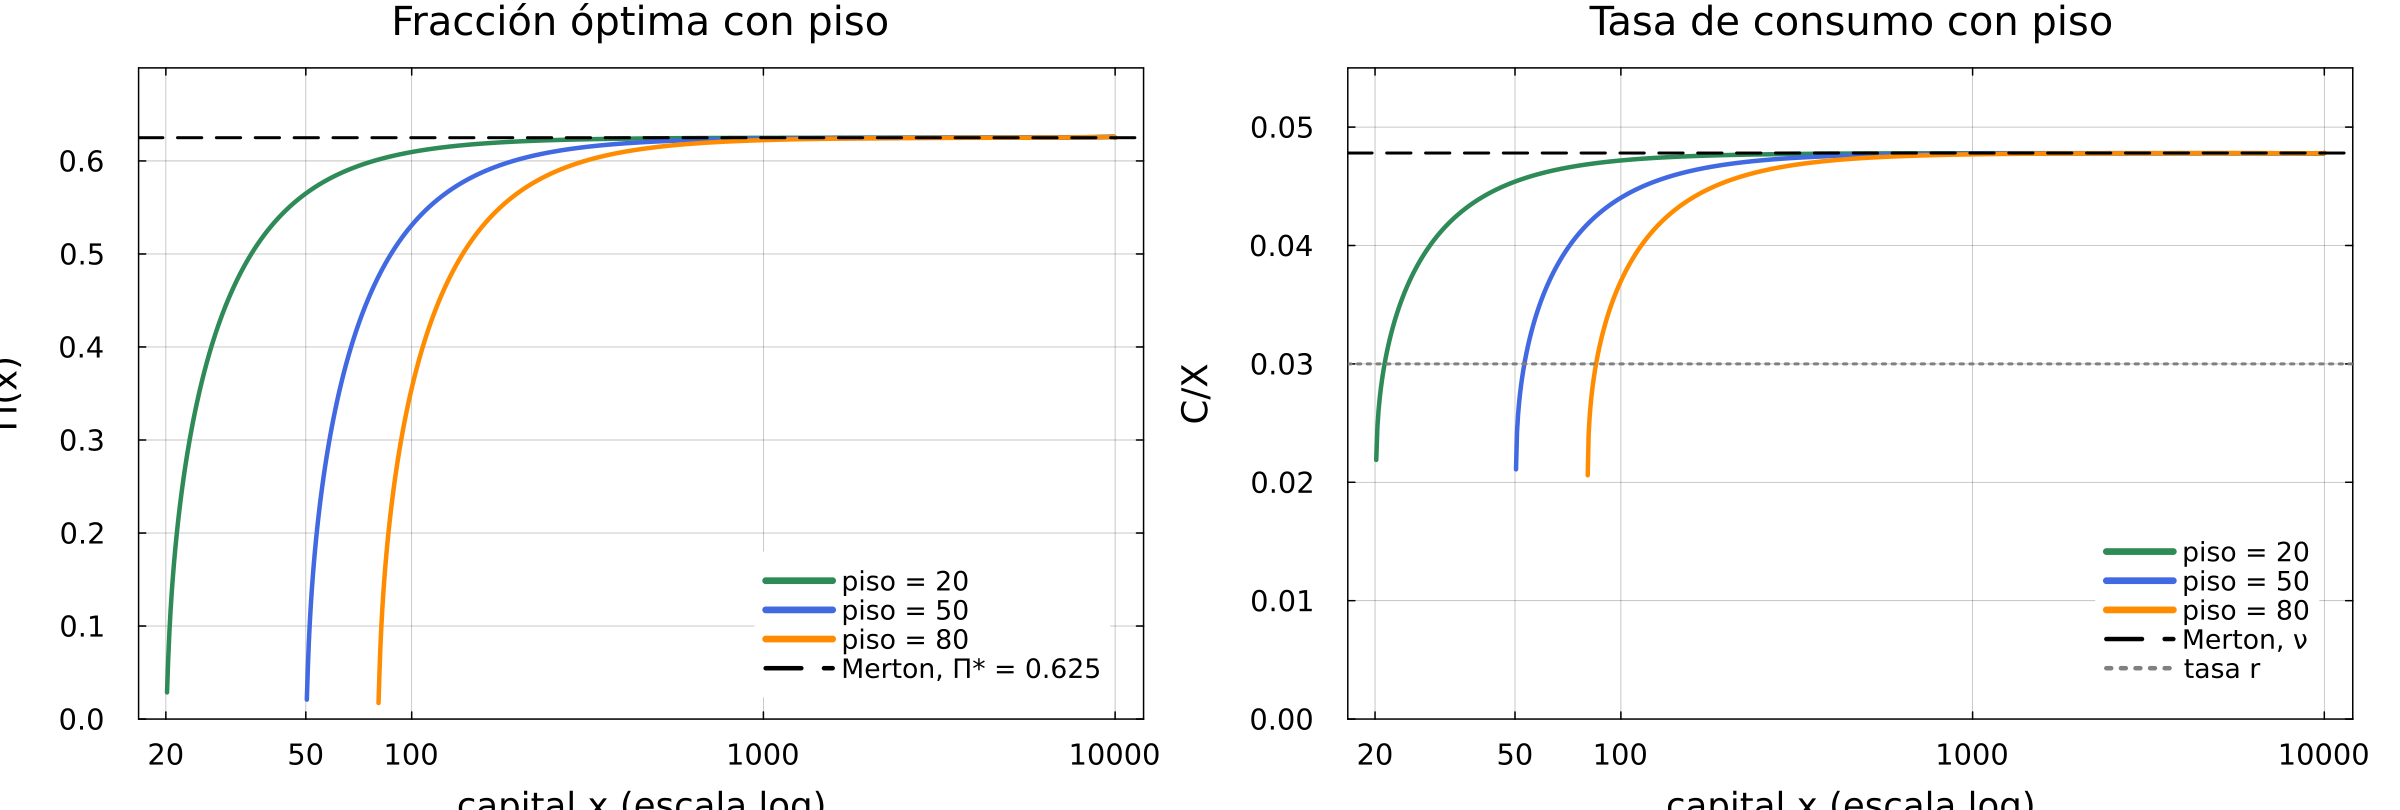

In [10]:
ejex = ([20, 50, 100, 1000, 10000], ["20", "50", "100", "1000", "10000"])   # marcas del eje x en escala log
q1 = plot(xlabel="capital x (escala log)", ylabel="Π(x)", title="Fracción óptima con piso", xscale=:log10,
          legend=:bottomright, ylims=(0, 0.7), xticks=ejex)
q2 = plot(xlabel="capital x (escala log)", ylabel="C/X", title="Tasa de consumo con piso", xscale=:log10,
          legend=:bottomright, ylims=(0, 0.055), xticks=ejex)
for (xl, col) in zip(pisos, [:seagreen, :royalblue, :darkorange])
    s = sols[xl]
    plot!(q1, s.x[2:end], s.Pi[2:end], color=col, label="piso = $(Int(xl))")
    plot!(q2, s.x[2:end], s.e[2:end], color=col, label="piso = $(Int(xl))")
end
hline!(q1, [Pim], color=:black, ls=:dash, lw=2, label="Merton, Π* = 0.625")
hline!(q2, [nu], color=:black, ls=:dash, lw=2, label="Merton, ν")
hline!(q2, [par.r], color=:gray, ls=:dot, lw=2, label="tasa r")
savefig(plot(q1, dpi=300), "figuras_poster/piso_fraccion.png")
savefig(plot(q2, dpi=300), "figuras_poster/piso_consumo.png")
plot(q1, q2, layout=(1, 2), size=(1600, 540))

El piso cambia el control: lejos del piso el inversionista actúa como Merton, pero al acercarse **reduce la fracción invertida casi a cero** y **consume menos que la tasa de interés** $r$. Así, cerca del piso el capital crece en forma casi determinista y se aleja de la liquidación: conviene sacrificar rentabilidad antes que perder la posibilidad de invertir. Cuanto más alto el piso, más se nota desde $x_0$: con $x_\ell=80$, en $x_0=100$ invierte solo 0.36 y su valor equivale a tener 85 de capital sin piso. Con $x_\ell=20$ el piso casi no importa ($x_{CE}=98.9$).

**Verificación por simulación.** Simulamos el capital con el control numérico (interpolado entre nodos) para $x_\ell=50$, detenemos cada trayectoria si toca el piso (y sumamos $e^{-\gamma\tau}\Psi(X_\tau)$), y a las que no lo tocan en 100 años les sumamos el valor numérico $e^{-\gamma T}V_\ell(X_T)$. Si la solución numérica es correcta, el promedio debe reproducir $V_\ell(x_0)$ (identidad de martingala, como en el avance 2).

In [11]:
# interpolación lineal en la malla uniforme y
interp(yq, y, v) = (k = y[2] - y[1]; j = clamp(floor(Int, (yq - y[1])/k) + 1, 1, length(y) - 1);
                    a = (yq - y[j])/k; (1 - a)*v[j] + a*v[j+1])

function mc_piso(s, xl; N=5_000, h=1/52, Tsim=100.0, semilla=8, P=par)
    rng = Xoshiro(semilla); K = round(Int, Tsim/h)
    Y = zeros(N); tocan = 0
    for i in 1:N
        x, acc, parado = P.x0, 0.0, false
        f0 = U(interp(log(x), s.y, s.e)*x)
        for k in 1:K
            ly = log(x); Pi = interp(ly, s.y, s.Pi); e = interp(ly, s.y, s.e)
            x *= exp((P.r + Pi*(P.mu - P.r) - e - 0.5*P.sigma^2*Pi^2)*h + P.sigma*Pi*sqrt(h)*randn(rng))
            if x <= xl                                           # se toca el piso: liquidación
                acc += h/2*f0 + exp(-P.gamma*k*h)*Psi(x); parado = true; tocan += 1
                break
            end
            f1 = exp(-P.gamma*k*h)*U(interp(log(x), s.y, s.e)*x)
            acc += h/2*(f0 + f1); f0 = f1
        end
        parado || (acc += exp(-P.gamma*K*h)*interp(log(x), s.y, s.W))
        Y[i] = acc
    end
    return mean(Y), 1.96*std(Y)/sqrt(N), tocan/N
end

s50 = sols[50.0]; i0 = argmin(abs.(s50.x .- par.x0))
m, ic, frac = mc_piso(s50, 50.0)
@printf("piso 50: Monte-Carlo = %.4f +- %.4f   vs   V_l(x0) numérico = %.4f;   fracción que toca el piso: %.4f\n", m, ic, s50.W[i0], frac)

piso 50: Monte-Carlo = 15.3797 +- 0.0483   vs   V_l(x0) numérico = 15.3879;   fracción que toca el piso: 0.0382


La simulación reproduce el valor numérico dentro del intervalo de confianza, así que la solución de la HJB con piso es consistente. Además, solo el 3.8% de las trayectorias toca el piso en 100 años: el control óptimo casi elimina la liquidación, como se veía en los gráficos.

In [12]:
# figura del reporte: tres paneles en una fila con letras más chicas
fig = plot(pe, pv, q1, layout=(1, 3), size=(1200, 340), titlefontsize=10, guidefontsize=9, tickfontsize=8,
           legendfontsize=6, bottom_margin=6Plots.mm, left_margin=5Plots.mm)
mkpath("figuras_final"); savefig(fig, "figuras_final/horizonte_parada.pdf");

## 6. Conclusiones y pendientes

**Conclusiones.**
1. Con horizonte finito el control óptimo sigue siendo $\Pi^*$ constante, pero la tasa de consumo $1/L(T-t)$ crece hacia $T$, y sin herencia explota como $1/(T-t)$. La HJB parabólica numérica converge a la solución explícita con orden 1.
2. El horizonte es un parámetro relevante: el problema se parece al de horizonte infinito solo cuando $T\gtrsim3/\nu\approx60$ años.
3. Un tiempo de parada aleatorio e independiente, $\tau\sim\text{Exp}(\lambda)$, equivale a aumentar el descuento a $\gamma+\lambda$: no cambia la fracción invertida y aumenta el consumo, y la herencia modera ese aumento.
4. Un tiempo de parada que depende del capital (piso de liquidación) rompe la homotecia: el control deja de ser constante y solo se puede obtener numéricamente. Cerca del piso conviene no invertir y consumir menos que el interés.

**Pendientes.**
* **Parada óptima**: que el inversionista elija $\tau$ (por ejemplo, cuándo retirarse del mercado pagando un costo). Es un problema de frontera libre, $\max\{\text{HJB},\ \Psi-V\}=0$, que se puede resolver agregando a la iteración de políticas la opción "parar" en cada nodo.
* Resolver numéricamente el caso sin herencia, que necesita pasos de tiempo que se achiquen cerca de $T$, donde el consumo explota.
* Combinar horizonte finito y piso, o usar un piso que crezca con el tiempo (un capital mínimo garantizado).